# Análise de Dados do E-commerce Brasileiro — Olist

## 1. Apresentação do projeto

Este projeto tem como objetivo analisar dados públicos de um e-commerce brasileiro, utilizando SQL e Python para investigar o comportamento dos pedidos, o desempenho das entregas e a satisfação dos clientes.

A análise utiliza o Brazilian E-Commerce Public Dataset by Olist, disponibilizado no Kaggle.

## 2. Objetivos da análise

- Investigar a evolução mensal dos pedidos.
- Analisar a distribuição dos pedidos por situação.
- Identificar cancelamentos e pedidos indisponíveis.
- Avaliar o desempenho das entregas.
- Comparar o desempenho logístico entre estados brasileiros.
- Investigar a relação entre atrasos e avaliações dos clientes.

## 3. Ferramentas utilizadas

- PostgreSQL
- Python
- Pandas
- Matplotlib
- Google Colab

## 4. Fonte dos dados

[Brazilian E-Commerce Public Dataset by Olist — Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)

## 5. Importação das bibliotecas e carregamento dos dados

Nesta etapa, são importadas as bibliotecas utilizadas na análise e carregados os arquivos do conjunto de dados da Olist para o ambiente Python.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

print("Projeto Olist iniciado com sucesso!")

print("Versão do Pandas:", pd.__version__)

Projeto Olist iniciado com sucesso!
Versão do Pandas: 2.2.3


In [6]:
import pandas as pd

pedidos = pd.read_csv('/content/olist_orders_dataset.csv')

print("Quantidade de linhas e colunas:")
print(pedidos.shape)

print("\nPrimeiras 5 linhas:")
display(pedidos.head())

Quantidade de linhas e colunas:
(99441, 8)

Primeiras 5 linhas:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


## 6. Exploração e qualidade dos dados

Nesta etapa, são avaliadas a estrutura do conjunto de dados, os tipos de informações disponíveis, os valores ausentes e a existência de registros duplicados.

O objetivo é compreender a qualidade dos dados antes de realizar as análises.

In [7]:
# 1. Verificar informações das colunas
print("INFORMAÇÕES DA TABELA")
pedidos.info()

# 2. Verificar valores ausentes
print("\nVALORES AUSENTES")
display(
    pedidos.isnull().sum().to_frame("quantidade_ausente")
)

# 3. Verificar pedidos duplicados
print("\nPEDIDOS DUPLICADOS")
print(pedidos["order_id"].duplicated().sum())

# 4. Verificar quantidade por situação do pedido
print("\nSITUAÇÃO DOS PEDIDOS")
display(
    pedidos["order_status"].value_counts().to_frame("quantidade")
)

INFORMAÇÕES DA TABELA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

VALORES AUSENTES


,quantidade_ausente
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0



PEDIDOS DUPLICADOS
0

SITUAÇÃO DOS PEDIDOS


,quantidade
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [8]:
colunas_data = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for coluna in colunas_data:
    pedidos[coluna] = pd.to_datetime(pedidos[coluna])

print("Tipos de dados atualizados:")
display(pedidos.dtypes)

Tipos de dados atualizados:


,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


In [9]:
print("Período dos pedidos:")
print("Primeiro pedido:", pedidos["order_purchase_timestamp"].min())
print("Último pedido:", pedidos["order_purchase_timestamp"].max())

Período dos pedidos:
Primeiro pedido: 2016-09-04 21:15:19
Último pedido: 2018-10-17 17:30:18


## 7. Evolução mensal dos pedidos

Nesta análise, investigamos a quantidade de pedidos realizados ao longo do tempo, identificando tendências de crescimento, variações mensais e períodos de maior movimentação.

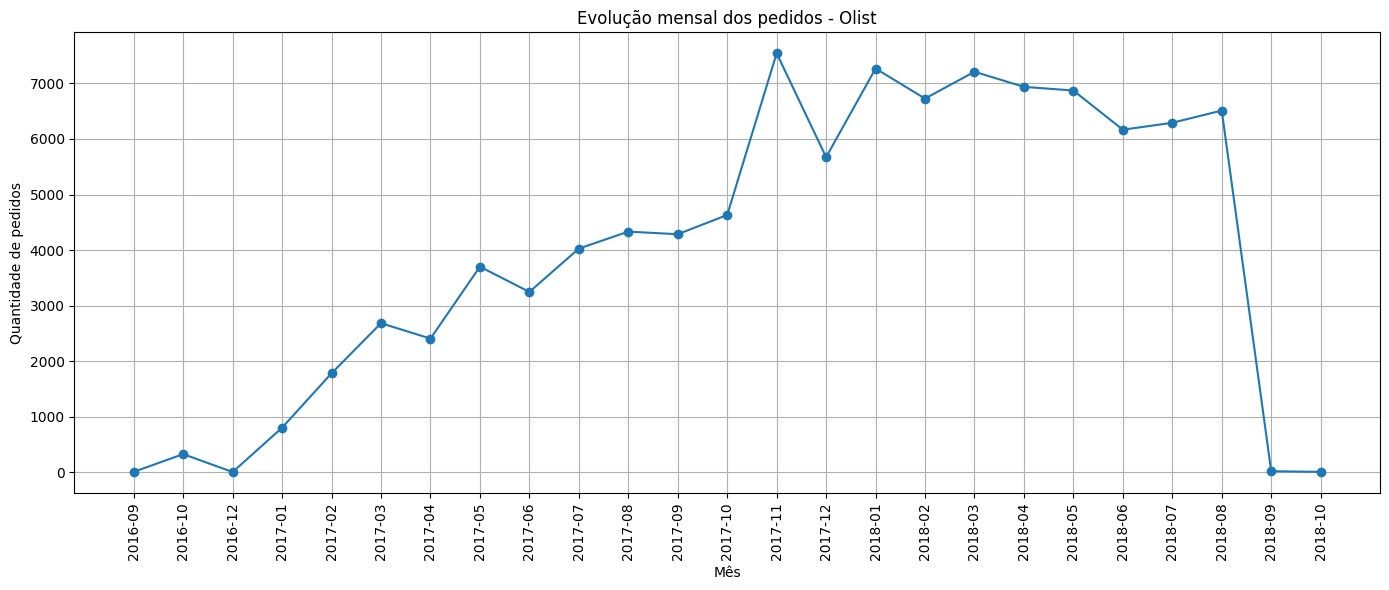

In [10]:
# Agrupar os pedidos por mês
pedidos["mes"] = (
    pedidos["order_purchase_timestamp"]
    .dt.to_period("M")
)

pedidos_mensais = (
    pedidos.groupby("mes")
    .size()
    .reset_index(name="quantidade_pedidos")
)

# Transformar o período em texto para o gráfico
pedidos_mensais["mes"] = pedidos_mensais["mes"].astype(str)

# Criar o gráfico
plt.figure(figsize=(14, 6))

plt.plot(
    pedidos_mensais["mes"],
    pedidos_mensais["quantidade_pedidos"],
    marker="o"
)

plt.title("Evolução mensal dos pedidos - Olist")
plt.xlabel("Mês")
plt.ylabel("Quantidade de pedidos")
plt.xticks(rotation=90)
plt.grid()
plt.tight_layout()
plt.show()

In [11]:
display(pedidos_mensais)

,mes,quantidade_pedidos
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


In [12]:
print(
    "Mês com mais pedidos:",
    pedidos_mensais.loc[
        pedidos_mensais["quantidade_pedidos"].idxmax()
    ].to_dict()
)

Mês com mais pedidos: {'mes': '2017-11', 'quantidade_pedidos': 7544}


## 8. Distribuição dos pedidos por situação

Nesta etapa, analisamos a quantidade e o percentual de pedidos em cada situação, como entregues, cancelados, enviados e indisponíveis.

O objetivo é compreender o desempenho geral dos pedidos na plataforma.

In [13]:
# Contar pedidos por situação
situacao_pedidos = (
    pedidos["order_status"]
    .value_counts()
    .reset_index()
)

situacao_pedidos.columns = [
    "situacao",
    "quantidade"
]

# Calcular percentual
situacao_pedidos["percentual"] = (
    situacao_pedidos["quantidade"] /
    len(pedidos) * 100
).round(2)

display(situacao_pedidos)

,situacao,quantidade,percentual
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


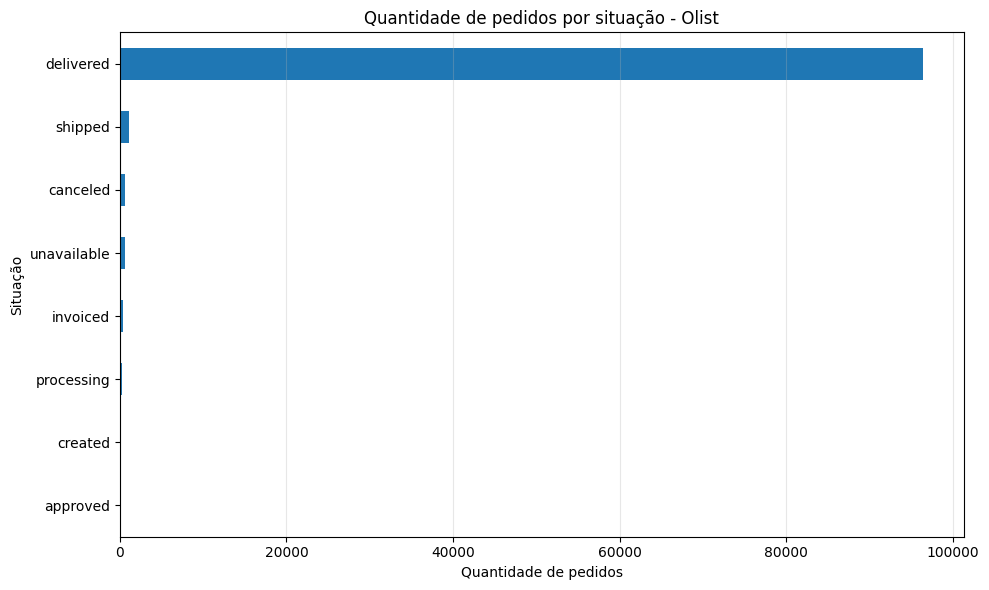

In [14]:
import matplotlib.pyplot as plt

situacao_pedidos = pedidos["order_status"].value_counts()

plt.figure(figsize=(10, 6))
situacao_pedidos.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Quantidade de pedidos por situação - Olist")
plt.xlabel("Quantidade de pedidos")
plt.ylabel("Situação")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Análise de cancelamentos e pedidos indisponíveis

Nesta análise, identificamos os pedidos cancelados ou indisponíveis e avaliamos sua representatividade em relação ao total de pedidos.

Também investigamos a evolução desses casos ao longo dos meses, buscando identificar períodos com maior ocorrência.

In [15]:
pedidos_problematicos = pedidos[
    pedidos["order_status"].isin(["canceled", "unavailable"])
]

quantidade = len(pedidos_problematicos)
percentual = (quantidade / len(pedidos)) * 100

print("Pedidos cancelados ou indisponíveis:", quantidade)
print("Percentual do total:", round(percentual, 2), "%")

Pedidos cancelados ou indisponíveis: 1234
Percentual do total: 1.24 %


In [16]:
pedidos_problematicos = pedidos[
    pedidos["order_status"].isin(["canceled", "unavailable"])
].copy()

pedidos_problematicos["mes"] = (
    pedidos_problematicos["order_purchase_timestamp"]
    .dt.to_period("M")
)

problemas_mensais = (
    pedidos_problematicos
    .groupby(["mes", "order_status"])
    .size()
    .unstack(fill_value=0)
)

problemas_mensais["total"] = problemas_mensais.sum(axis=1)

display(problemas_mensais)

order_status,canceled,unavailable,total
mes,,,
2016-09,2,0,2
2016-10,24,7,31
2017-01,3,10,13
2017-02,17,45,62
2017-03,33,32,65
2017-04,18,9,27
2017-05,29,31,60
2017-06,16,24,40
2017-07,28,52,80


In [17]:
# Quantidade total de pedidos por mês
total_mensal = (
    pedidos.groupby(
        pedidos["order_purchase_timestamp"].dt.to_period("M")
    )
    .size()
    .rename("total_pedidos")
)

# Quantidade de pedidos cancelados ou indisponíveis por mês
problemas_mensais_total = (
    pedidos_problematicos.groupby("mes")
    .size()
    .rename("pedidos_problematicos")
)

# Juntar os resultados
comparacao_mensal = pd.concat(
    [total_mensal, problemas_mensais_total],
    axis=1
).fillna(0)

comparacao_mensal["pedidos_problematicos"] = (
    comparacao_mensal["pedidos_problematicos"].astype(int)
)

# Calcular percentual de problemas
comparacao_mensal["percentual_problemas"] = (
    comparacao_mensal["pedidos_problematicos"]
    / comparacao_mensal["total_pedidos"] * 100
).round(2)

comparacao_mensal.index = comparacao_mensal.index.astype(str)

display(
    comparacao_mensal.sort_values(
        "percentual_problemas",
        ascending=False
    )
)

,total_pedidos,pedidos_problematicos,percentual_problemas
2018-10,4,4,100.00
2018-09,16,15,93.75
2016-09,4,2,50.00
2016-10,324,31,9.57
2017-02,1780,62,3.48
2017-03,2682,65,2.42
2017-07,4026,80,1.99
2017-10,4631,84,1.81
2017-01,800,13,1.62
2017-05,3700,60,1.62


In [18]:
meses_relevantes = comparacao_mensal[
    comparacao_mensal["total_pedidos"] >= 500
].copy()

display(
    meses_relevantes.sort_values(
        "percentual_problemas",
        ascending=False
    )
)

,total_pedidos,pedidos_problematicos,percentual_problemas
2017-02,1780,62,3.48
2017-03,2682,65,2.42
2017-07,4026,80,1.99
2017-10,4631,84,1.81
2017-05,3700,60,1.62
2017-01,800,13,1.62
2017-11,7544,121,1.60
2018-02,6728,103,1.53
2018-08,6512,91,1.40
2017-08,4331,59,1.36


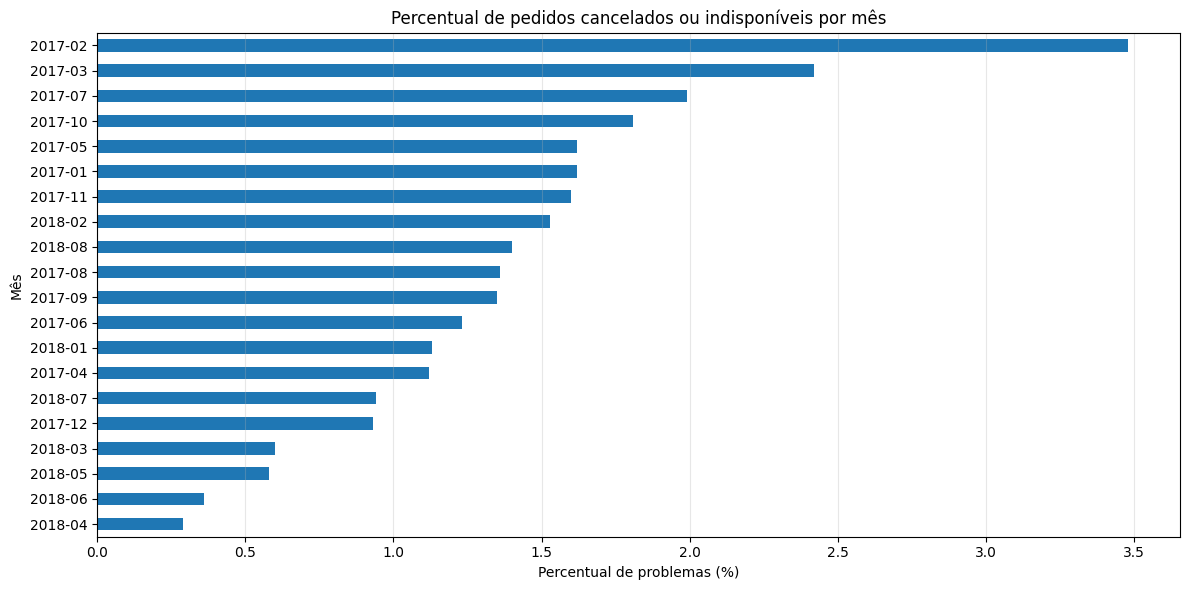

In [19]:
plt.figure(figsize=(12, 6))

meses_relevantes["percentual_problemas"].sort_values().plot(
    kind="barh"
)

plt.title("Percentual de pedidos cancelados ou indisponíveis por mês")
plt.xlabel("Percentual de problemas (%)")
plt.ylabel("Mês")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Desempenho das entregas

Nesta etapa, analisamos o tempo necessário para a entrega dos pedidos e comparamos a data real de entrega com a data estimada.

O objetivo é identificar o percentual de entregas atrasadas e entregas realizadas dentro do prazo ou antecipadamente.

In [20]:
# Considerar apenas pedidos entregues
entregas = pedidos[
    (pedidos["order_status"] == "delivered") &
    (pedidos["order_delivered_customer_date"].notna()) &
    (pedidos["order_estimated_delivery_date"].notna())
].copy()

# Calcular o prazo real de entrega em dias
entregas["dias_entrega"] = (
    entregas["order_delivered_customer_date"] -
    entregas["order_purchase_timestamp"]
).dt.days

# Verificar se houve atraso
entregas["resultado_entrega"] = (
    entregas["order_delivered_customer_date"] >
    entregas["order_estimated_delivery_date"]
).map({
    True: "Atrasado",
    False: "No prazo ou antecipado"
})

# Resumo
resumo_entregas = (
    entregas["resultado_entrega"]
    .value_counts()
    .reset_index()
)

resumo_entregas.columns = ["resultado", "quantidade"]

resumo_entregas["percentual"] = (
    resumo_entregas["quantidade"] / len(entregas) * 100
).round(2)

display(resumo_entregas)

,resultado,quantidade,percentual
0,No prazo ou antecipado,88644,91.89
1,Atrasado,7826,8.11


In [21]:
tempo_entrega = (
    entregas.groupby("resultado_entrega")["dias_entrega"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(tempo_entrega)

,count,mean,median,min,max
resultado_entrega,,,,,
Atrasado,7826,31.06,29.0,2,209
No prazo ou antecipado,88644,10.42,9.0,0,70


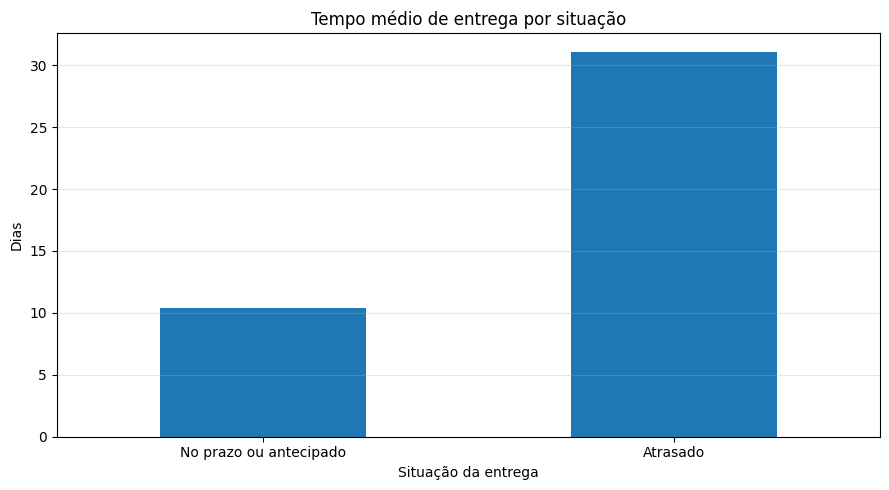

In [22]:
medias_entrega = entregas.groupby(
    "resultado_entrega"
)["dias_entrega"].mean().sort_values()

plt.figure(figsize=(9, 5))

medias_entrega.plot(kind="bar")

plt.title("Tempo médio de entrega por situação")
plt.xlabel("Situação da entrega")
plt.ylabel("Dias")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/tempo_medio_entrega.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Análise de atrasos por estado

Nesta etapa, comparamos o desempenho das entregas entre os estados brasileiros, considerando o volume de pedidos, a quantidade de atrasos e o percentual de entregas atrasadas.

O objetivo é identificar diferenças regionais e possíveis oportunidades de melhoria logística.

In [24]:
# Carregar os dados dos clientes
clientes = pd.read_csv("/content/olist_customers_dataset.csv")

# Adicionar o estado do cliente aos dados de entrega
entregas_estado = entregas.merge(
    clientes[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

# Agrupar os resultados por estado
analise_estados = (
    entregas_estado
    .groupby("customer_state")
    .agg(
        total_pedidos=("order_id", "count"),
        pedidos_atrasados=(
            "resultado_entrega",
            lambda x: (x == "Atrasado").sum()
        ),
        media_dias_entrega=("dias_entrega", "mean")
    )
)

# Calcular percentual de atrasos
analise_estados["percentual_atrasos"] = (
    analise_estados["pedidos_atrasados"]
    / analise_estados["total_pedidos"] * 100
).round(2)

analise_estados["media_dias_entrega"] = (
    analise_estados["media_dias_entrega"].round(2)
)

# Considerar estados com pelo menos 500 pedidos
analise_estados = analise_estados[
    analise_estados["total_pedidos"] >= 500
]

display(
    analise_estados.sort_values(
        "percentual_atrasos",
        ascending=False
    )
)

,total_pedidos,pedidos_atrasados,media_dias_entrega,percentual_atrasos
customer_state,,,,
MA,717,141,21.12,19.67
CE,1279,196,20.82,15.32
BA,3256,457,18.87,14.04
RJ,12350,1664,14.85,13.47
PA,946,117,23.32,12.37
ES,1995,244,15.33,12.23
MS,701,81,15.19,11.55
PB,517,57,19.95,11.03
PE,1593,172,17.97,10.80


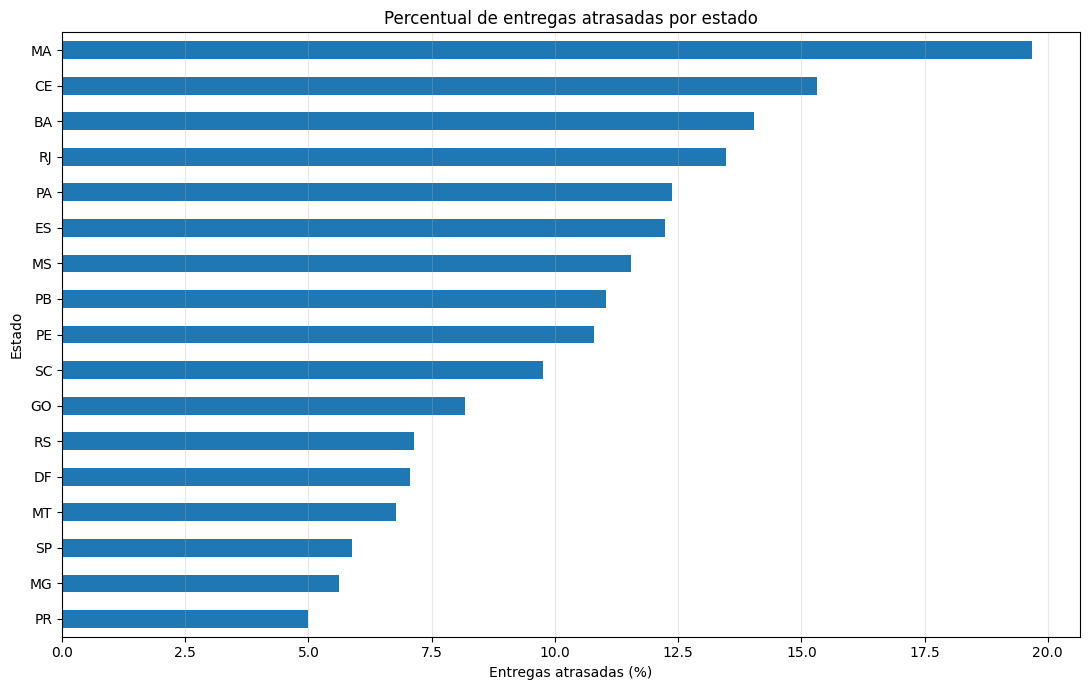

In [25]:
plt.figure(figsize=(11, 7))

analise_estados["percentual_atrasos"].sort_values().plot(
    kind="barh"
)

plt.title("Percentual de entregas atrasadas por estado")
plt.xlabel("Entregas atrasadas (%)")
plt.ylabel("Estado")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/atrasos_por_estado.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 12. Relação entre atrasos e avaliações dos clientes

Nesta análise, investigamos a relação entre o prazo de entrega e a satisfação dos clientes, comparando as notas das avaliações associadas a entregas atrasadas e entregas realizadas dentro do prazo ou antecipadamente.

O objetivo é compreender como o desempenho logístico está associado à experiência dos consumidores.

In [26]:
avaliacoes = pd.read_csv(
    "/content/olist_order_reviews_dataset.csv"
)

# Selecionar apenas as colunas necessárias
avaliacoes = avaliacoes[
    ["order_id", "review_score"]
]

# Relacionar avaliações com entregas
entregas_avaliacoes = entregas.merge(
    avaliacoes,
    on="order_id",
    how="inner"
)

print("Quantidade de registros:", len(entregas_avaliacoes))

display(entregas_avaliacoes.head())

Quantidade de registros: 96353


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,mes,dias_entrega,resultado_entrega,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10,8,No prazo ou antecipado,4
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07,13,No prazo ou antecipado,4
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08,9,No prazo ou antecipado,5
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11,13,No prazo ou antecipado,5
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02,2,No prazo ou antecipado,5


In [27]:
avaliacao_entrega = (
    entregas_avaliacoes
    .groupby("resultado_entrega")
    .agg(
        quantidade=("review_score", "count"),
        nota_media=("review_score", "mean"),
        nota_mediana=("review_score", "median")
    )
)

avaliacao_entrega["nota_media"] = (
    avaliacao_entrega["nota_media"].round(2)
)

display(avaliacao_entrega)

,quantidade,nota_media,nota_mediana
resultado_entrega,,,
Atrasado,7700,2.57,2.0
No prazo ou antecipado,88653,4.29,5.0


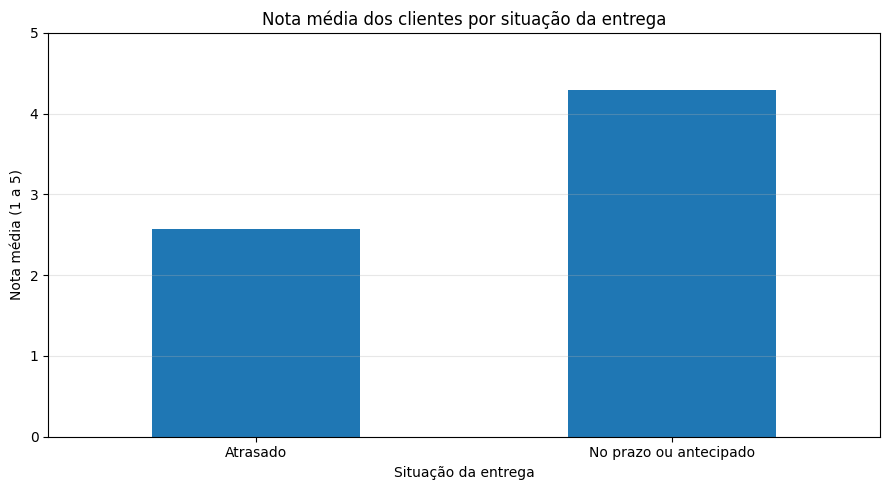

In [28]:
notas_por_entrega = (
    entregas_avaliacoes
    .groupby("resultado_entrega")["review_score"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(9, 5))

notas_por_entrega.plot(kind="bar")

plt.title("Nota média dos clientes por situação da entrega")
plt.xlabel("Situação da entrega")
plt.ylabel("Nota média (1 a 5)")
plt.xticks(rotation=0)
plt.ylim(0, 5)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/avaliacoes_por_entrega.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
entregas_avaliacoes["avaliacao_negativa"] = (
    entregas_avaliacoes["review_score"] <= 2
)

taxa_avaliacao_negativa = (
    entregas_avaliacoes
    .groupby("resultado_entrega")
    .agg(
        total_avaliacoes=("review_score", "count"),
        avaliacoes_negativas=("avaliacao_negativa", "sum")
    )
)

taxa_avaliacao_negativa["percentual_negativo"] = (
    taxa_avaliacao_negativa["avaliacoes_negativas"]
    / taxa_avaliacao_negativa["total_avaliacoes"] * 100
).round(2)

display(taxa_avaliacao_negativa)

,total_avaliacoes,avaliacoes_negativas,percentual_negativo
resultado_entrega,,,
Atrasado,7700,4160,54.03
No prazo ou antecipado,88653,8186,9.23


## 13. Conclusões e recomendações

### Principais resultados

A análise dos dados do e-commerce da Olist permitiu identificar os seguintes resultados:

- **Volume de pedidos:** foram identificados 99.441 pedidos no período analisado, entre setembro de 2016 e outubro de 2018.
- **Situação dos pedidos:** aproximadamente 97,02% dos pedidos foram entregues.
- **Cancelamentos e indisponibilidade:** 1,24% dos pedidos foram cancelados ou ficaram indisponíveis.
- **Desempenho das entregas:** entre os pedidos entregues com datas válidas, 8,11% chegaram após a data estimada.
- **Diferenças regionais:** o Maranhão apresentou o maior percentual de atrasos (19,67%) entre os estados considerados na análise.
- **Satisfação dos clientes:** as avaliações negativas foram proporcionalmente mais frequentes nos registros associados a entregas atrasadas (54,03%) do que nos registros de entregas realizadas no prazo ou antecipadamente (9,23%).

### Recomendações para o negócio

Com base nos resultados, algumas oportunidades de melhoria foram identificadas:

1. Investigar os fatores logísticos associados aos atrasos, especialmente nas regiões com maiores percentuais.
2. Avaliar os processos de transporte e distribuição para reduzir o tempo de entrega.
3. Monitorar os pedidos cancelados e indisponíveis para identificar possíveis falhas operacionais.
4. Acompanhar as avaliações dos clientes como indicador da qualidade da experiência de compra.
5. Criar indicadores periódicos para monitorar o desempenho logístico e a satisfação dos consumidores.

### Considerações finais

O projeto demonstra como a análise de dados pode transformar grandes volumes de informações em indicadores relevantes para a tomada de decisão.

A combinação de PostgreSQL, Python, Pandas e Matplotlib permitiu explorar diferentes dimensões do negócio, identificar padrões e apontar oportunidades de melhoria.